# Mesh Base Size Study

In [1]:
import re
import glob # find all files whose name patches a pattern (eg. force_reports_*mm.txt)
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path('.') # Current folder
OUTPUT_XLSX = DATA_DIR / 'mesh_study_results.xlsx'

## 1) File Parsing

In [2]:
# Reusable Pattern Objects

# Label, Value, Unit (groups here are named by ?P<label>)
LINE_RE = re.compile(r'^(?P<label>.+?)\s{2,}(?P<value>-?\d+\.\d+)\s*(?P<unit>[A-Za-z^0-9/]*)\s*$')

# mesh size in file name (eg. 30, 40, ...)
FILENAME_RE = re.compile(r'force_reports_(\d+)mm\.txt$')

In [3]:
def parse_report(path):
    """Parse ONE force_reports_*mm.txt file into a dict of {label: value} plus metadata.
    Args:
        path: path to one force report file (eg. force_reports_60mm.txt)
    Returns:
        values: dict[str, float], maps each parameter label to its numeric value
        units: dict[str, str], maps each parameter label to its unit
        run_name
    """
    values = {}
    units = {}
    run_name = None

    with open(path) as f: #open() is built-in python func, gives file object f (to .readline(), .read(), ...)
        for line in f:
            line = line.rstrip('\n') # remove newline char from right end
            
            if line.startswith('# BFR report export'):
                run_name = line.split('run:', 1)[-1].strip() #Split once on "run:", then get last elem, then remove surrounding white space
                continue
            if not line.strip() or line.startswith('#'): #line.strip() returns [] when line is all whitespace; This checks if line is empty or starts with #
                continue

            m = LINE_RE.match(line) # m = match object
            if not m: 
                raise ValueError(
                    f'Could not parse line in {path.name!r}: {line!r}'
                )
    
            label = m.group('label').strip()
            values[label] = float(m.group('value'))
            units[label] = m.group('unit').strip()

    return values, units, run_name

In [4]:
# Find all files in directory with this format
files = sorted(DATA_DIR.glob('force_reports_*mm.txt')) # returns an iterable

if not files:
    raise FileNotFoundError(FileNotFoundError(f'No force_reports_*mm.txt files found in {DATA_DIR.resolve()}'))

records = {} # dict of all dicts...
units_ref = {}
run_names = {}
mesh_sizes = {}

for path in files:
    m = FILENAME_RE.search(path.name) #returns mesh size
    if not m:
        raise ValueError(
            f'Filename does not match expected pattern {path.name}'
        )
    mesh_mm = int(m.group(1))

    values, units, run_name = parse_report(path)

    col_label = f'{mesh_mm}mm' # will be a DataFrame column later
    records[col_label] = values # values is also a dict

    units_ref.update(units) #units_ref collects all units from across all reports
    run_names[col_label] = run_name
    mesh_sizes[col_label] = mesh_mm

print(f'Parsed {len(files)} reports:')
for col, mesh_mm in mesh_sizes.items():
    print(f'  {col:>6}  ({len(records[col])} metrics)  run={run_names[col]}')

Parsed 5 reports:
    30mm  (47 metrics)  run=YL_FC_MeshBase30mm_Straight_20260913_1200
    35mm  (47 metrics)  run=YL_FC_MeshBase35mm_Straight_20260913_1200
    40mm  (47 metrics)  run=YL_FC_MeshBase40mm_Straight_20260913_0900
    50mm  (47 metrics)  run=YL_FC_MeshBase50mm_Straight_20260913_1200
    60mm  (47 metrics)  run=YL_FC_MeshBase60mm_Straight_20260913_1200


Records is used to build up the DataFrame, with columns as 60mm, 50mm, ...
records = {

    "60mm": {
        "Full Car DF": -245.89,
        "Full Car Drag": 82.12,
        "Full Car CoP": 31.5,
    },

    "50mm": {
        "Full Car DF": -250.31,
        "Full Car Drag": 83.45,
        "Full Car CoP": 31.8,
    },

    "40mm": {
        "Full Car DF": -252.10,
        "Full Car Drag": 83.80,
        "Full Car CoP": 32.0,
    }
}

## 2) Build Values Table

In [5]:
#Order Columns by mesh size, coarse to fine (Array of str)
ordered_cols = sorted(
    records.keys(),
    key=lambda c: mesh_sizes[c],
    reverse=False
)

In [6]:
raw_df = pd.DataFrame(records)
raw_df = raw_df[ordered_cols]
raw_df.index.name = 'Metric'

In [7]:
#Check all columns have same metrics
metric_sets = {}
for col in ordered_cols:
    metric_sets[col] = set(records[col].keys())

base_set = metric_sets[ordered_cols[0]] # pick one report as reference
for col, s in metric_sets.items():
    if s != base_set:
        print(f'WARNING: {col} has different metrics than {ordered_cols[0]}: {base_set.symmetric_difference(s)}')

In [8]:
raw_df.head()

,30mm,35mm,40mm,50mm,60mm
Metric,,,,,
Full Car CoP (Meters),0.753659,0.770022,0.773179,0.774862,0.780920
Full Car CoP,47.851338,48.890292,49.090728,49.197569,49.582203
Radiator MF Rate,0.284180,0.283339,0.262068,0.259041,0.276996
Inlet MF Averaged Pressure,56.192229,59.658696,47.086410,47.855238,50.249196
Outlet MF Averaged Pressure,37.245495,40.438251,29.068681,29.256874,29.761003


## 3) Plotting raw DF

In [9]:
df_components = [
    m for m in raw_df.index
    if m.endswith('DF') and m != 'Full Car DF'
]
df_components

['RW DF',
 'UT DF',
 'FW DF',
 'Body DF',
 'Wheel DF',
 'Whisker DF',
 'Radiator DF',
 'EL4 DF',
 'EL5 DF',
 'EL6 DF',
 'EL7 DF',
 'EL8 DF',
 'Endplate DF',
 'Swan Neck DF',
 'Carbon Rod DF']

In [10]:
drag_components = [
    m for m in raw_df.index
    if m.endswith('Drag') and m != 'Full Car Drag'
]
drag_components

['Body Drag',
 'FW Drag',
 'RW Drag',
 'UT Drag',
 'Wheel Drag',
 'Whisker Drag',
 'Radiator Drag',
 'Carbon Rod Drag',
 'EL4 Drag',
 'EL5 Drag',
 'EL6 Drag',
 'EL7 Drag',
 'EL8 Drag',
 'Endplate Drag',
 'Swan Neck Drag']

In [11]:
# Set up X axis
mesh_order = sorted(ordered_cols, key=lambda c: mesh_sizes[c])
x = [mesh_sizes[c] for c in mesh_order]
x

[30, 35, 40, 50, 60]

In [12]:
mesh_order

['30mm', '35mm', '40mm', '50mm', '60mm']

In [13]:
# PLOTTING
def plot_component_group(metrics, ylabel, title, filename):
    fig, ax = plt.subplots(figsize=(7, 7))
    for metric in metrics:
        y = raw_df.loc[metric, mesh_order] # gives metric for all mesh sizes
        ax.plot(x, y, marker='o', label=metric)

    #formatting
    ax.set_xlabel('Mesh Base Size (mm)')
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(DATA_DIR / filename, dpi=150, bbox_inches='tight')
    return fig

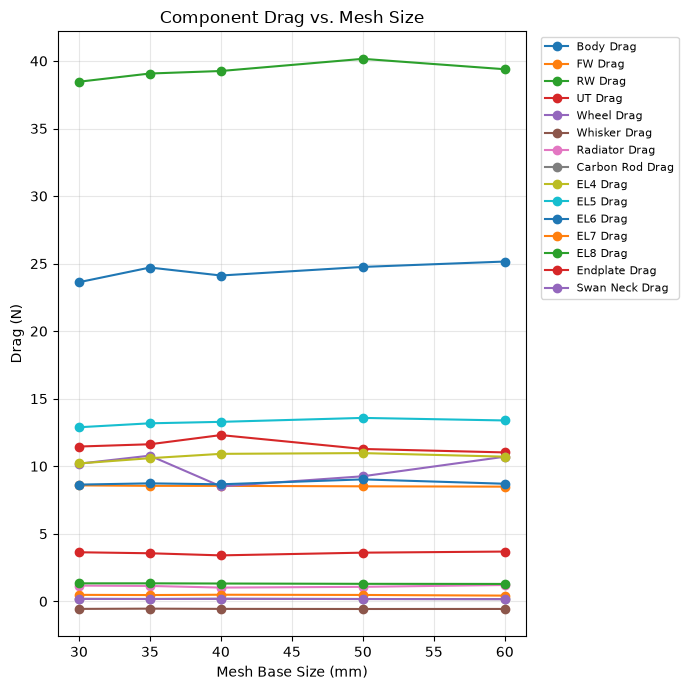

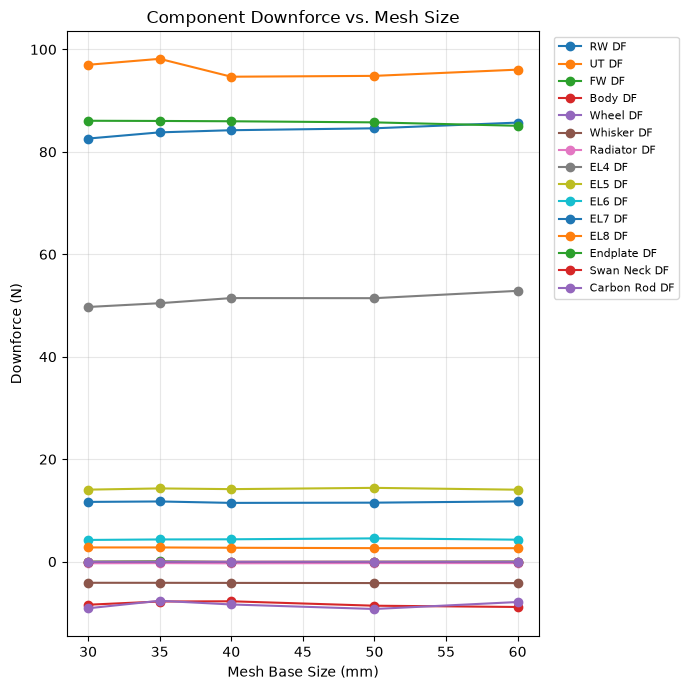

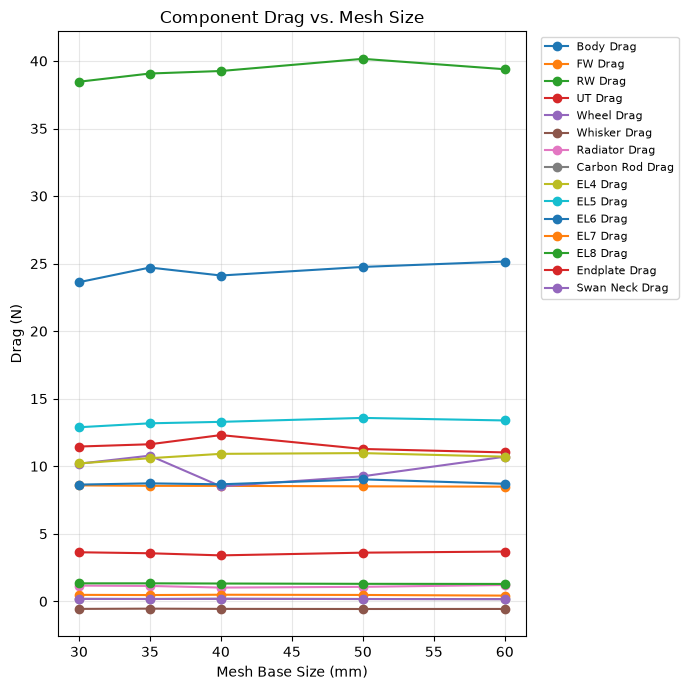

In [14]:
# Plot 1: component downforce
plot_component_group(df_components, 'Downforce (N)', 'Component Downforce vs. Mesh Size', 'plot_df_components.png')

# Plot 2: component drag
plot_component_group(drag_components, 'Drag (N)', 'Component Drag vs. Mesh Size', 'plot_drag_components.png')

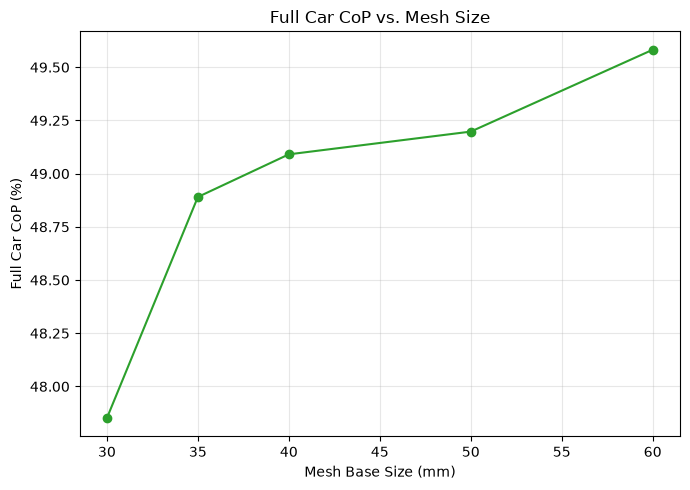

In [15]:
# Plot 3: CoP%
fig_cop, ax_cop = plt.subplots(figsize=(7, 5))
y_cop = raw_df.loc['Full Car CoP', mesh_order]
ax_cop.plot(x, y_cop, marker='o', color='tab:green')
ax_cop.set_xlabel('Mesh Base Size (mm)')
ax_cop.set_ylabel('Full Car CoP (%)')
ax_cop.set_title('Full Car CoP vs. Mesh Size')
ax_cop.grid(alpha=0.3)
fig_cop.tight_layout()
fig_cop.savefig(DATA_DIR / 'plot_cop_percentage.png', dpi=150)

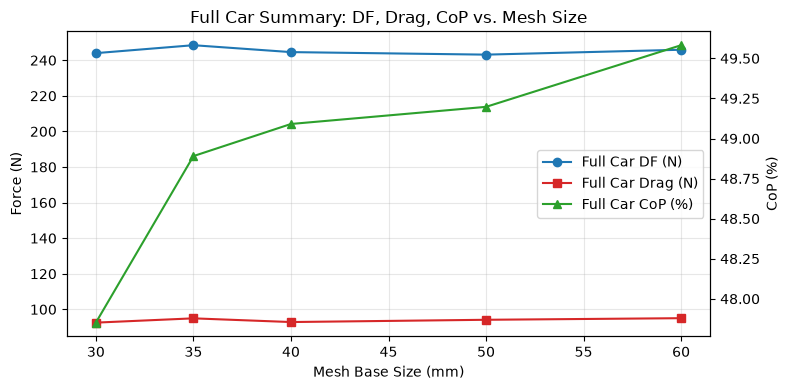

In [16]:
# Plot 4: Full Car DF + Drag (N, left axis) and Full Car CoP (%, right axis) together.
# Two y-axes are required since force (N) and CoP (%) aren't the same unit.
fig_summary, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(x, raw_df.loc['Full Car DF', mesh_order], marker='o', color='tab:blue', label='Full Car DF (N)')
ax1.plot(x, raw_df.loc['Full Car Drag', mesh_order], marker='s', color='tab:red', label='Full Car Drag (N)')
ax1.set_xlabel('Mesh Base Size (mm)')
ax1.set_ylabel('Force (N)')
ax1.grid(alpha=0.3)

# create second axis (sharing the same x axis)
ax2 = ax1.twinx()
ax2.plot(x, raw_df.loc['Full Car CoP', mesh_order], marker='^', color='tab:green', label='Full Car CoP (%)')
ax2.set_ylabel('CoP (%)')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='best')
ax1.set_title('Full Car Summary: DF, Drag, CoP vs. Mesh Size')
fig_summary.tight_layout()
fig_summary.savefig(DATA_DIR / 'plot_full_car_summary.png', dpi=150)

## 4) Calculate & Plot Deltas
% delta = (mesh - finest(30mm)) / |finest(30mm)| * 100
All deltas are with respect to 30mm

In [17]:
delta_df = pd.DataFrame(index=raw_df.index)
delta_df.head()

""
Metric
Full Car CoP (Meters)
Full Car CoP
Radiator MF Rate
Inlet MF Averaged Pressure
Outlet MF Averaged Pressure


In [18]:
# Each mesh size vs. the finest mesh (30mm baseline)
baseline_col = mesh_order[0]  # finest mesh size, e.g. '30mm'
baseline_vals = raw_df[baseline_col]

for col in ordered_cols:
    if col == baseline_col:
        continue
    step_label = f'{col} vs {baseline_col} (%)'
    delta_df[step_label] = (raw_df[col] - baseline_vals) / baseline_vals.abs() * 100 #calculates delta (.abs() so downforce is a positive num)

delta_df.head()

,35mm vs 30mm (%),40mm vs 30mm (%),50mm vs 30mm (%),60mm vs 30mm (%)
Metric,,,,
Full Car CoP (Meters),2.171141,2.590031,2.813341,3.617153
Full Car CoP,2.171212,2.590084,2.813361,3.617172
Radiator MF Rate,-0.295939,-7.780984,-8.846154,-2.527975
Inlet MF Averaged Pressure,6.168944,-16.204766,-14.836555,-10.576254
Outlet MF Averaged Pressure,8.572194,-21.953834,-21.448556,-20.095026


In [19]:
markers = [
    'o', 's', '^', 'D', 'v',
    'P', 'X', '<', '>', 'p',
    '*', 'h', 'H', '8', 'd'
]

linestyles = ['-', '--', '-.', ':']

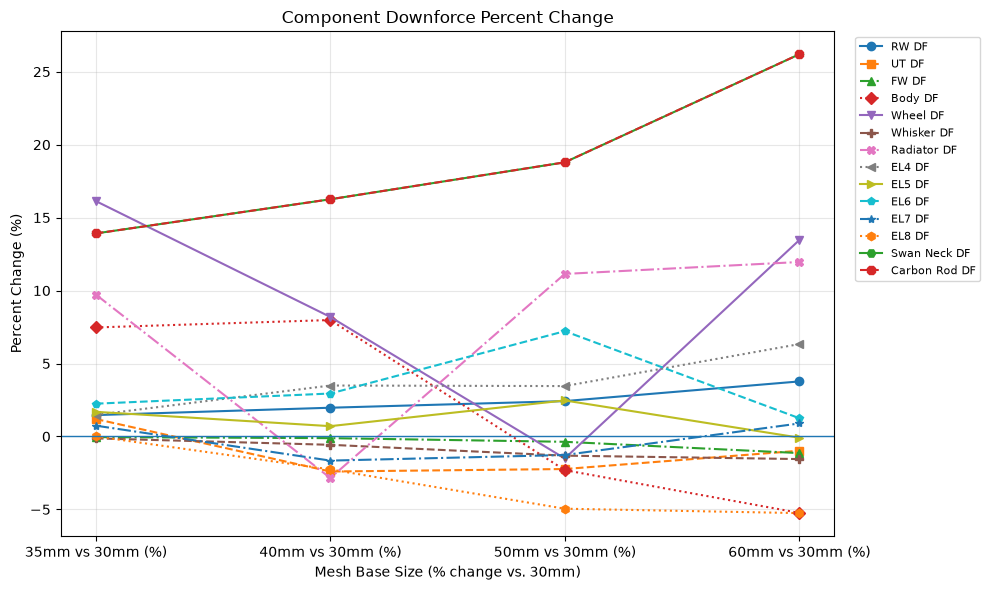

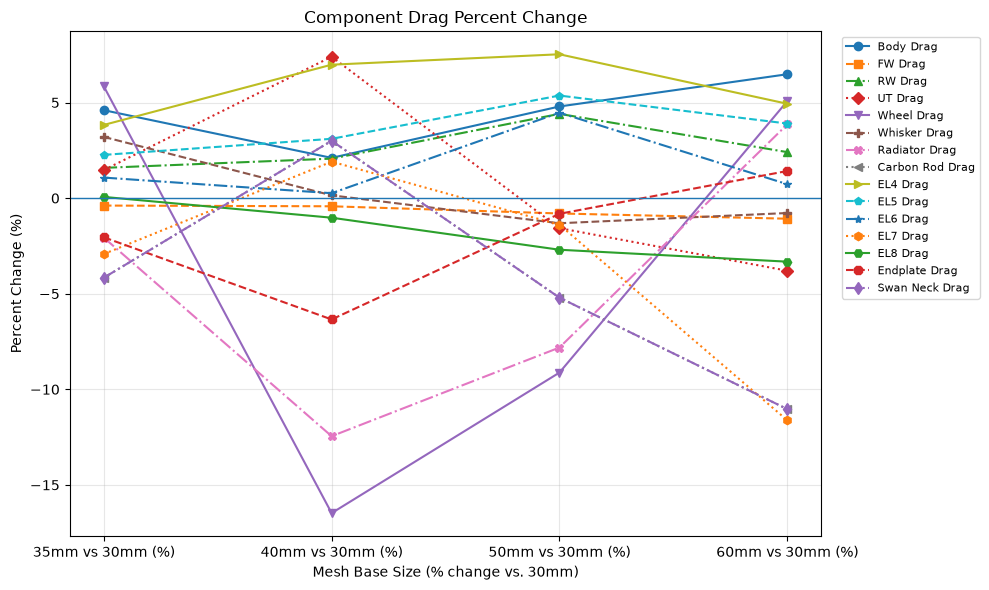

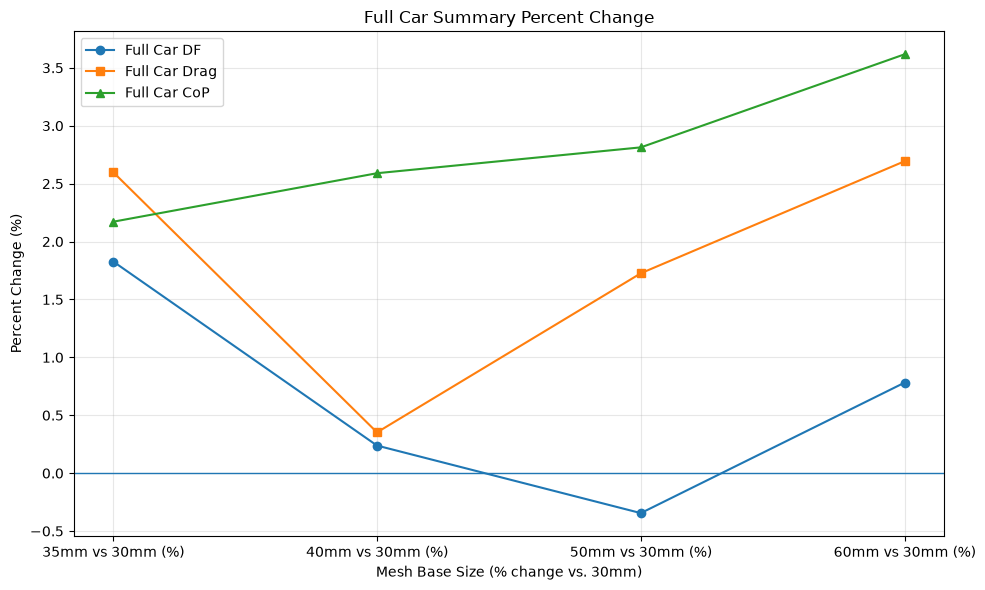

In [20]:
# Note: Endplate DF is excluded from this percent-change plot. Its raw force is
# nearly zero (~0.001-0.07 N across all mesh sizes), so tiny absolute noise between
# runs produces wildly exaggerated percent changes that swamp the other components.
df_components_pct = [m for m in df_components if m != 'Endplate DF']

# Plot 1: Component Downforce percent delta
fig_df_delta, ax_df_delta = plt.subplots(figsize=(10, 6))

for i, metric in enumerate(df_components_pct):
    y = delta_df.loc[metric]

    ax_df_delta.plot(
        delta_df.columns,
        y,
        marker=markers[i],
        linestyle=linestyles[i % len(linestyles)],
        label=metric
    )

ax_df_delta.axhline(0, linewidth=1)
ax_df_delta.set_xlabel('Mesh Base Size (% change vs. 30mm)')
ax_df_delta.set_ylabel('Percent Change (%)')
ax_df_delta.set_title('Component Downforce Percent Change')
ax_df_delta.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
ax_df_delta.grid(alpha=0.3)

fig_df_delta.tight_layout()
fig_df_delta.savefig(
    DATA_DIR / 'plot_delta_df_components.png',
    dpi=150,
    bbox_inches='tight'
)

# Plot 2: Component Drag percent delta
fig_drag_delta, ax_drag_delta = plt.subplots(figsize=(10, 6))

for i, metric in enumerate(drag_components):
    y = delta_df.loc[metric]

    ax_drag_delta.plot(
        delta_df.columns,
        y,
        marker=markers[i],
        linestyle=linestyles[i % len(linestyles)],
        label=metric
    )

ax_drag_delta.axhline(0, linewidth=1)
ax_drag_delta.set_xlabel('Mesh Base Size (% change vs. 30mm)')
ax_drag_delta.set_ylabel('Percent Change (%)')
ax_drag_delta.set_title('Component Drag Percent Change')
ax_drag_delta.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
ax_drag_delta.grid(alpha=0.3)

fig_drag_delta.tight_layout()
fig_drag_delta.savefig(
    DATA_DIR / 'plot_delta_drag_components.png',
    dpi=150,
    bbox_inches='tight'
)


# Plot 3: Full Car summary percent delta (DF, Drag, CoP together; all in % so one axis works)
fig_summary_delta, ax_summary_delta = plt.subplots(figsize=(10, 6))

for marker, metric in zip(['o', 's', '^'], ['Full Car DF', 'Full Car Drag', 'Full Car CoP']):
    ax_summary_delta.plot(
        delta_df.columns,
        delta_df.loc[metric],
        marker=marker,
        label=metric
    )

ax_summary_delta.axhline(0, linewidth=1)
ax_summary_delta.set_xlabel('Mesh Base Size (% change vs. 30mm)')
ax_summary_delta.set_ylabel('Percent Change (%)')
ax_summary_delta.set_title('Full Car Summary Percent Change')
ax_summary_delta.legend(loc='best')
ax_summary_delta.grid(alpha=0.3)

fig_summary_delta.tight_layout()
fig_summary_delta.savefig(
    DATA_DIR / 'plot_delta_full_car_summary.png',
    dpi=150,
    bbox_inches='tight'
)

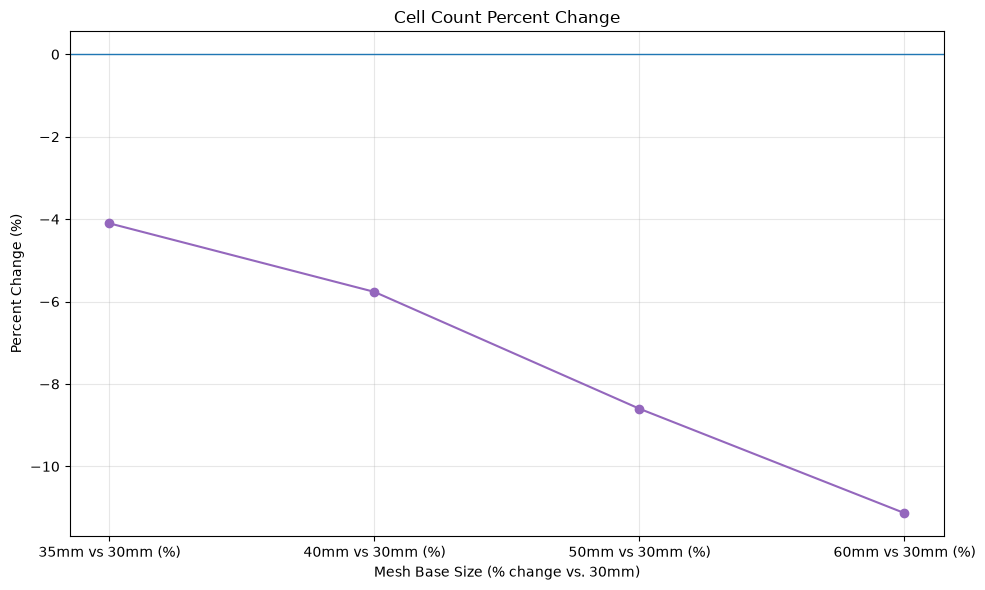

In [21]:
# Plot 4: Cell Count percent delta (mesh density change relative to 30mm baseline)
fig_cellcount_delta, ax_cellcount_delta = plt.subplots(figsize=(10, 6))

ax_cellcount_delta.plot(
    delta_df.columns,
    delta_df.loc['Cell Count'],
    marker='o',
    color='tab:purple'
)

ax_cellcount_delta.axhline(0, linewidth=1)
ax_cellcount_delta.set_xlabel('Mesh Base Size (% change vs. 30mm)')
ax_cellcount_delta.set_ylabel('Percent Change (%)')
ax_cellcount_delta.set_title('Cell Count Percent Change')
ax_cellcount_delta.grid(alpha=0.3)

fig_cellcount_delta.tight_layout()
fig_cellcount_delta.savefig(
    DATA_DIR / 'plot_delta_cell_count.png',
    dpi=150,
    bbox_inches='tight'
)

## Export
Writes `mesh_study_results.xlsx` with a `Raw Values` sheet and a `Percent Delta` sheet.

In [22]:
with pd.ExcelWriter(OUTPUT_XLSX, engine='openpyxl') as writer:
    raw_df.to_excel(writer, sheet_name='Raw Values')
    delta_df.to_excel(writer, sheet_name='Percent Delta')

    for sheet_name, df in [('Raw Values', raw_df), ('Percent Delta', delta_df)]:
        ws = writer.sheets[sheet_name]
        ws.column_dimensions['A'].width = 26
        for i, col in enumerate(df.columns, start=2):
            ws.column_dimensions[ws.cell(row=1, column=i).column_letter].width = 18

print(f'Wrote {OUTPUT_XLSX.resolve()}')

Wrote /Users/amyliu/Desktop/BFR/BFR Vault/B27 Studies/mesh-base-study/mesh_study_results.xlsx


# Wall Time
Cost side of the study: how much run time each mesh base size takes, and whether the accuracy gained from a finer mesh is worth it.

Source: `mesh_walltime_summary.xlsx` (times are file mtimes from the cluster, not PBS accounting, so expect some noise from node allocation/load).

**Caveat:** the 40mm run stopped at 909 iterations vs. 1250 for the others, so its total/solve time is *not* comparable. Cost comparisons use **solve time per iteration**.

## 5) Load Wall Time Table

In [23]:
WALLTIME_XLSX = DATA_DIR / 'mesh_walltime_summary.xlsx'

wall_raw = pd.read_excel(WALLTIME_XLSX)

# Sheet has footnote rows under the table; keep only rows whose first column is a mesh size
size_col = 'Mesh Base Size (mm)'
wall_raw[size_col] = pd.to_numeric(wall_raw[size_col], errors='coerce')
wall_raw = wall_raw.dropna(subset=[size_col])

wall_df = pd.DataFrame({
    'Iterations Run': wall_raw['Iterations Run'].astype(int),
    'Solve Time (min)': pd.to_timedelta(wall_raw['Solve Time']).dt.total_seconds() / 60,
    'Post-Processing Time (min)': pd.to_timedelta(wall_raw['Post-Processing Time']).dt.total_seconds() / 60,
    'Total Wall Time (min)': pd.to_timedelta(wall_raw['Total Wall Time']).dt.total_seconds() / 60,
    'Solve Time / Iteration (s)': wall_raw['Solve Time / Iteration (s)'],
})
wall_df.index = [f'{int(s)}mm' for s in wall_raw[size_col]]  # same keys as raw_df columns
wall_df.index.name = 'Mesh Size'

# Check wall time and force reports cover the same mesh sizes
missing = set(mesh_order) ^ set(wall_df.index)
if missing:
    print(f'WARNING: mesh sizes only in one of force reports / wall time: {missing}')

wall_df = wall_df.loc[mesh_order]  # finest -> coarsest, same as the rest of the notebook
wall_df['Cell Count (M)'] = raw_df.loc['Cell Count', mesh_order] / 1e6
wall_df

,Iterations Run,Solve Time (min),Post-Processing Time (min),Total Wall Time (min),Solve Time / Iteration (s),Cell Count (M)
Mesh Size,,,,,,
30mm,1250,79.433333,13.200000,92.633333,3.81280,39.094249
35mm,1250,71.966667,13.066667,85.033333,3.45440,37.490479
40mm,909,56.116667,11.150000,67.266667,3.70407,36.840164
50mm,1250,72.216667,12.800000,85.016667,3.46640,35.731616
60mm,1250,67.133333,12.650000,79.783333,3.22240,34.741504


## 6) Derived Columns
% change vs. the finest mesh (30mm), same convention as the force deltas.

In [24]:
wall_base = wall_df.loc[baseline_col]

wall_delta_df = pd.DataFrame(index=wall_df.index)
for c in ['Solve Time / Iteration (s)', 'Total Wall Time (min)', 'Cell Count (M)']:
    wall_delta_df[f'{c} vs {baseline_col} (%)'] = (wall_df[c] - wall_base[c]) / wall_base[c] * 100

wall_delta_df = wall_delta_df.drop(index=baseline_col)
wall_delta_df.round(2)

,Solve Time / Iteration (s) vs 30mm (%),Total Wall Time (min) vs 30mm (%),Cell Count (M) vs 30mm (%)
Mesh Size,,,
35mm,-9.40,-8.20,-4.10
40mm,-2.85,-27.38,-5.77
50mm,-9.09,-8.22,-8.60
60mm,-15.48,-13.87,-11.13


## 7) Plot Wall Time

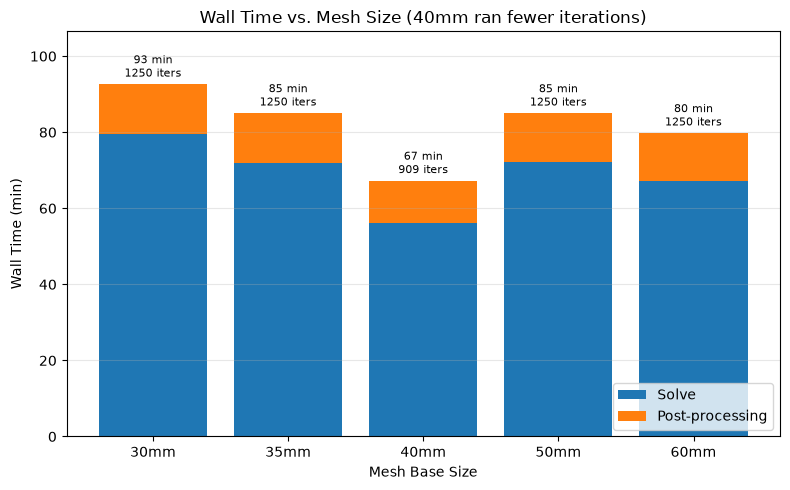

In [25]:
# Plot 1: Wall time by mesh size (solve + post-processing), iterations annotated
fig_wall, ax_wall = plt.subplots(figsize=(8, 5))
xpos = range(len(mesh_order))

ax_wall.bar(xpos, wall_df['Solve Time (min)'], color='tab:blue', label='Solve')
ax_wall.bar(xpos, wall_df['Post-Processing Time (min)'], bottom=wall_df['Solve Time (min)'],
            color='tab:orange', label='Post-processing')

for i, col in enumerate(mesh_order):
    total = wall_df.loc[col, 'Total Wall Time (min)']
    iters = wall_df.loc[col, 'Iterations Run']
    ax_wall.text(i, total + 1, f'{total:.0f} min\n{iters} iters', ha='center', va='bottom', fontsize=8)

ax_wall.set_xticks(list(xpos))
ax_wall.set_xticklabels(mesh_order)
ax_wall.set_ylim(0, wall_df['Total Wall Time (min)'].max() * 1.15)
ax_wall.set_xlabel('Mesh Base Size')
ax_wall.set_ylabel('Wall Time (min)')
ax_wall.set_title('Wall Time vs. Mesh Size (40mm ran fewer iterations)')
ax_wall.legend(loc='lower right')
ax_wall.grid(alpha=0.3, axis='y')
fig_wall.tight_layout()
fig_wall.savefig(DATA_DIR / 'plot_walltime.png', dpi=150)

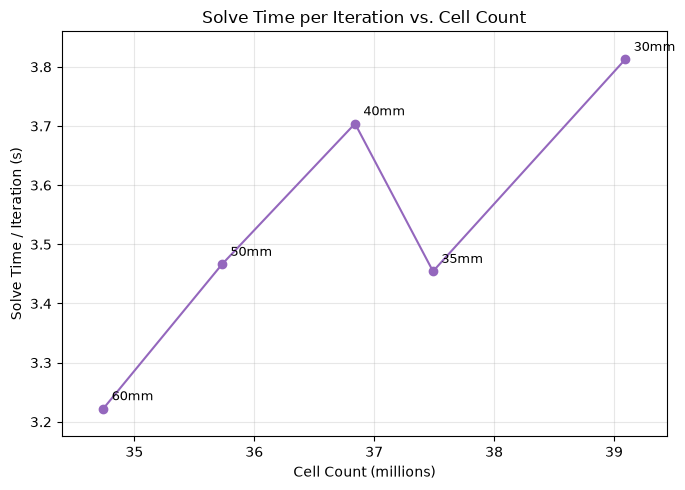

In [26]:
# Plot 2: Solve time per iteration vs. cell count
fig_tpi, ax_tpi = plt.subplots(figsize=(7, 5))
ax_tpi.plot(wall_df['Cell Count (M)'], wall_df['Solve Time / Iteration (s)'], marker='o', color='tab:purple')

for col in mesh_order:
    ax_tpi.annotate(col, (wall_df.loc[col, 'Cell Count (M)'], wall_df.loc[col, 'Solve Time / Iteration (s)']),
                    textcoords='offset points', xytext=(6, 6), fontsize=9)

ax_tpi.margins(x=0.08, y=0.08)
ax_tpi.set_xlabel('Cell Count (millions)')
ax_tpi.set_ylabel('Solve Time / Iteration (s)')
ax_tpi.set_title('Solve Time per Iteration vs. Cell Count')
ax_tpi.grid(alpha=0.3)
fig_tpi.tight_layout()
fig_tpi.savefig(DATA_DIR / 'plot_time_per_iteration.png', dpi=150)

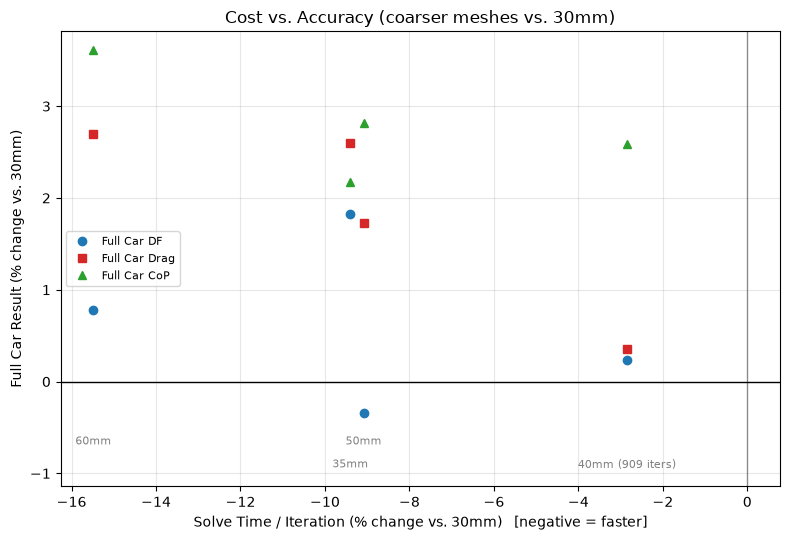

In [27]:
# Plot 3: Cost vs. accuracy. x = how much cheaper than 30mm (solve time / iteration), y = how far the
# full car results drift from 30mm. Each point is one coarser mesh size.
cost_col = f'Solve Time / Iteration (s) vs {baseline_col} (%)'
sizes_plot = wall_delta_df.index  # coarser than baseline only

fig_ca, ax_ca = plt.subplots(figsize=(8, 5.5))
for i, (metric, color) in enumerate([('Full Car DF', 'tab:blue'), ('Full Car Drag', 'tab:red'), ('Full Car CoP', 'tab:green')]):
    y = [delta_df.loc[metric, f'{s} vs {baseline_col} (%)'] for s in sizes_plot]
    ax_ca.plot(wall_delta_df[cost_col], y, marker=markers[i], color=color, linestyle='none', label=metric)

# Label each mesh size in a strip below the data; stagger vertically so neighbours (e.g. 35mm/50mm) don't overlap
ymin, ymax = ax_ca.get_ylim()
ax_ca.set_ylim(ymin - 0.6, ymax)
for k, s in enumerate(wall_delta_df[cost_col].sort_values().index):
    label = f'{s} ({wall_df.loc[s, "Iterations Run"]} iters)' if wall_df.loc[s, 'Iterations Run'] != wall_df.loc[baseline_col, 'Iterations Run'] else s
    ax_ca.annotate(label, (wall_delta_df.loc[s, cost_col], ymin - 0.05 - 0.25 * (k % 2)),
                   va='top', ha='center', fontsize=8, color='gray')

ax_ca.axhline(0, linewidth=1, color='k')
ax_ca.axvline(0, linewidth=1, color='k', alpha=0.4)
ax_ca.set_xlabel(f'Solve Time / Iteration (% change vs. {baseline_col})   [negative = faster]')
ax_ca.set_ylabel(f'Full Car Result (% change vs. {baseline_col})')
ax_ca.set_title('Cost vs. Accuracy (coarser meshes vs. 30mm)')
ax_ca.legend(loc='best', fontsize=8)
ax_ca.grid(alpha=0.3)
fig_ca.tight_layout()
fig_ca.savefig(DATA_DIR / 'plot_cost_vs_accuracy.png', dpi=150)

## Export Wall Time
Adds a `Wall Time` sheet to `mesh_study_results.xlsx` (run after the Export cell above, which rewrites the file).

In [28]:
wall_out = wall_df.join(wall_delta_df)

with pd.ExcelWriter(OUTPUT_XLSX, engine='openpyxl', mode='a', if_sheet_exists='replace') as writer:
    wall_out.to_excel(writer, sheet_name='Wall Time')
    ws = writer.sheets['Wall Time']
    ws.column_dimensions['A'].width = 14
    for i in range(2, len(wall_out.columns) + 2):
        ws.column_dimensions[ws.cell(row=1, column=i).column_letter].width = 30

print(f'Added Wall Time sheet to {OUTPUT_XLSX.resolve()}')

Added Wall Time sheet to /Users/amyliu/Desktop/BFR/BFR Vault/B27 Studies/mesh-base-study/mesh_study_results.xlsx
